<a href="https://colab.research.google.com/github/zhengyangsu/Computer-Vision-Project-Overview/blob/main/ComputerVisionProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

## Setup: environment and paths

Run this cell first. It detects whether you are on **Google Colab**, **Windows** or **Mac**, picks the base folder (Google Drive or a local folder) and defines every path used below. To change where things live, edit `STORAGE` / `BASE_DIR_OVERRIDE` at the top of the cell.

In [ ]:
# =============================================================================
# SETUP: detect the environment and define EVERY path once. Run this cell first.
# Everything below uses these variables; no other cell defines a path.
# =============================================================================
import os, sys, glob, string, platform

# ---- 1. Your choices (the only part you ever need to edit) ------------------
STORAGE = 'auto'          # 'auto'  -> Google Drive if available, else a local folder
                          # 'drive' -> insist on Google Drive (Colab mount, or Drive for desktop)
                          # 'local' -> local disk (Colab: /content, fast but lost when the session ends)
BASE_DIR_OVERRIDE = None  # or your own folder, e.g. r'D:\ML\Colab_Notebooks'  or  '/Users/me/Colab_Notebooks'
FOLDER = 'Colab_Notebooks'
run_name = 'train'        # only used if you skip training and load an earlier run (e.g. 'train2')

# ---- 2. Detect where we are running -----------------------------------------
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OS_NAME = {'Windows': 'Windows', 'Darwin': 'Mac'}.get(platform.system(), 'Linux')
home = os.path.expanduser('~')


def find_local_drive():
    """Google Drive for desktop ('My Drive') on this computer, or None."""
    if OS_NAME == 'Windows':
        candidates = [f'{letter}:/My Drive' for letter in string.ascii_uppercase[2:]]  # C: .. Z:
    elif OS_NAME == 'Mac':
        candidates = glob.glob(os.path.join(home, 'Library/CloudStorage/GoogleDrive-*/My Drive'))
        candidates += [os.path.join(home, 'Google Drive/My Drive'), os.path.join(home, 'Google Drive')]
    else:
        candidates = [os.path.join(home, 'Google Drive')]
    return next((c for c in candidates if os.path.isdir(c)), None)


# ---- 3. Pick the base folder --------------------------------------------------
if BASE_DIR_OVERRIDE:
    root = BASE_DIR_OVERRIDE
elif IN_COLAB:
    root = os.path.join('/content/drive/MyDrive' if STORAGE in ('auto', 'drive') else '/content', FOLDER)
else:
    drive_root = find_local_drive()
    if STORAGE == 'drive' and drive_root is None:
        raise FileNotFoundError("STORAGE='drive' but Google Drive for desktop was not found. "
                                "Install it, or set BASE_DIR_OVERRIDE to a folder.")
    use_drive = STORAGE in ('auto', 'drive') and drive_root is not None
    root = os.path.join(drive_root if use_drive else home, FOLDER)

base_dir = os.path.abspath(os.path.expanduser(root))

if IN_COLAB and base_dir.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# ---- 4. Every path the notebook uses ------------------------------------------
dataset_url = ('https://github.com/zhengyangsu/Computer-Vision-Project-Overview/'
               'releases/download/v1.0/Cycling_Hand_Signals_Dataset.zip')

splits = ['train', 'valid', 'test']

# original dataset (images and labels together in each split)
data_dir = os.path.join(base_dir, 'Cycling_Hand_Signals_Dataset')
split_dirs = {s: os.path.join(data_dir, s) for s in splits}
src_images = {s: os.path.join(split_dirs[s], 'images') for s in splits}
src_labels = {s: os.path.join(split_dirs[s], 'labels') for s in splits}

# YOLO layout: Final_data/images/<split> and Final_data/labels/<split>
final_dir = os.path.join(data_dir, 'Final_data')
image_dir = os.path.join(final_dir, 'images')
label_dir = os.path.join(final_dir, 'labels')
final_images = {s: os.path.join(image_dir, s) for s in splits}
final_labels = {s: os.path.join(label_dir, s) for s in splits}

# training outputs
config_path = os.path.join(base_dir, 'config.yaml')
project_dir = os.path.join(base_dir, 'workbench')
run_dir = os.path.join(project_dir, run_name)
best_pt = os.path.join(run_dir, 'weights', 'best.pt')

# ---- 5. Create the folders ----------------------------------------------------
for folder in [base_dir, project_dir, *final_images.values(), *final_labels.values()]:
    os.makedirs(folder, exist_ok=True)

print(f'Environment : {"Colab" if IN_COLAB else "Local"} / {OS_NAME}')
print(f'base_dir    : {base_dir}')
print(f'data_dir    : {data_dir}')
print(f'final_dir   : {final_dir}')
print(f'project_dir : {project_dir}')
print(f'config_path : {config_path}')

Importing required Libraries

In [ ]:
from PIL import Image
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import glob
import xml.etree.ElementTree as ET
import shutil

# Dataset Description






# Data  

### Classification:  
0: Caution  
1: Cyclist  
2: Left Turn  
3: Right Turn  
4: Stop

In [ ]:
import tempfile
import urllib.request
import zipfile


def download_dataset(url, dest):
    """Download the zip and unpack it into dest (works on Colab, Windows and Mac)."""
    if os.path.isdir(os.path.join(dest, 'train')):
        print(f'Dataset already exists at {dest}, skipping download.')
        return
    os.makedirs(dest, exist_ok=True)
    with tempfile.TemporaryDirectory() as tmp:
        zip_path = os.path.join(tmp, 'dataset.zip')
        print('Downloading dataset ...')
        urllib.request.urlretrieve(url, zip_path)
        print('Unzipping ...')
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest)
    print('Done.')


download_dataset(dataset_url, data_dir)
print(os.listdir(data_dir))

# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction



The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

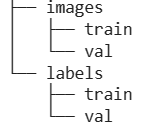


The YOLO folder structure (`Final_data/images/<split>` and `Final_data/labels/<split>`) is created in the setup cell at the top.

Copy TXT files and jpg files from the train folder to the folders created.

In [ ]:
# Names of the subfolders inside each original split.
# The paths themselves (src_images, src_labels, final_images, final_labels) come from the setup cell.


def copy_files(src_folder, dst_folder, extensions):
    """Copy files with the given extensions from src_folder to dst_folder."""
    if os.path.isdir(dst_folder) and os.listdir(dst_folder):
        print(f'  skipped {dst_folder} (already has {len(os.listdir(dst_folder))} files)')
        return 0

    os.makedirs(dst_folder, exist_ok=True)
    count = 0
    for file in os.listdir(src_folder):
        if os.path.splitext(file)[1].lower() in extensions:
            shutil.copy(os.path.join(src_folder, file), dst_folder)
            count += 1
    return count


for split in splits:
    n_img = copy_files(src_images[split], final_images[split], ('.jpg', '.jpeg', '.png'))
    n_lbl = copy_files(src_labels[split], final_labels[split], ('.txt',))
    print(f'{split}: copied {n_img} images, {n_lbl} labels')

Visualizing somme pictures from the dataset

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(final_images['train'])):
    img = cv2.imread(os.path.join(final_images['train'], image), 1)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) #color conversion
    plt.imshow(img)
    plt.show()

    if idx == 1:
        break

## Creating Dataframe from txt labels
Creating Dataframes from txt files


In [ ]:
class_names = ['Caution', 'Cyclist', 'Left Turn', 'Right Turn', 'Stop']

rows = []
for split in splits:
    label_folder = src_labels[split]
    for file in os.listdir(label_folder):
        if not file.endswith('.txt'):
            continue
        with open(os.path.join(label_folder, file)) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:          # skip blank or malformed lines
                    continue
                rows.append({
                    'split': split,
                    'name': os.path.splitext(file)[0],
                    'class': int(parts[0]),
                    'x_center': float(parts[1]),
                    'y_center': float(parts[2]),
                    'box_width': float(parts[3]),
                    'box_height': float(parts[4]),
                })

df = pd.DataFrame(rows)
df['label'] = df['class'].map(dict(enumerate(class_names)))
#display(df.head())
cols = ['split', 'class', 'label', 'x_center', 'y_center', 'box_width', 'box_height', 'name'] #reorder columns
df = df[cols]
display(df.sample(10, random_state=0))
print(df['split'].value_counts())

Sanity Check

In [ ]:
# Class balance per split
print(df.groupby(['split', 'label']).size().unstack(fill_value=0), end="\n\n")

# Images with no boxes
n_labeled = df.groupby('split')['name'].nunique()
print(n_labeled, end="\n\n")

# Sanity check: bb between 0 and 1
print(df[['x_center', 'y_center', 'box_width', 'box_height']].describe())

label  Caution  Cyclist  Left Turn  Right Turn  Stop
split                                               
test       247      569         86         120   126
train     1674     3808        681         777   860
valid      448     1111        198         252   247

split
test      623
train    4316
valid    1260
Name: name, dtype: int64

           x_center      y_center     box_width    box_height
count  11204.000000  11204.000000  11204.000000  11204.000000
mean       0.483925      0.517520      0.167775      0.488912
std        0.170823      0.115574      0.092325      0.302894
min        0.051562      0.148438      0.010156      0.004687
25%        0.342187      0.448437      0.100000      0.214648
50%        0.457813      0.533594      0.150000      0.435937
75%        0.637500      0.595313      0.210938      0.776563
max        0.953125      0.976562      0.620313      1.000000


In [ ]:
#train_df = df[df['split'] == 'train'].reset_index(drop=True)
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'valid']
test_df = df[df['split'] == 'test']

print('Train')
display(train_df.head(5))
print('\n\nVal')
display(val_df.head(5))
print('\n\nTest')
display(test_df.sample(5))



Train


,split,class,label,x_center,y_center,box_width,box_height,name
0,train,1,Cyclist,0.390625,0.634375,0.157812,0.487500,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...
1,train,1,Cyclist,0.051562,0.701562,0.103125,0.596875,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...
2,train,1,Cyclist,0.334375,0.428125,0.183594,0.728125,2nd-Edited-mp4_frame4164_jpg.rf.ee23e2da58794d...
3,train,2,Left Turn,0.367188,0.275000,0.142969,0.378125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
4,train,2,Left Turn,0.813281,0.270313,0.125781,0.384375,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...




Val


,split,class,label,x_center,y_center,box_width,box_height,name
7800,valid,1,Cyclist,0.328125,0.446875,0.161719,0.699219,2nd-Edited-mp4_frame4189_jpg.rf.5d90cee59ccfd1...
7801,valid,1,Cyclist,0.771094,0.532813,0.406250,0.934375,2nd-Edited-mp4_frame6149_jpg.rf.013fd67d2d978b...
7802,valid,1,Cyclist,0.440625,0.574219,0.211719,0.851562,2nd-Edited-mp4_frame6149_jpg.rf.013fd67d2d978b...
7803,valid,0,Caution,0.696094,0.510938,0.175000,0.350000,3rd-edited-mp4_frame2263_jpg.rf.3deb6a7fc4d9cb...
7804,valid,0,Caution,0.710938,0.522656,0.206250,0.472656,3rd-edited-mp4_frame4986_jpg.rf.171eeb6f29a903...




Test


,split,class,label,x_center,y_center,box_width,box_height,name
10192,test,2,Left Turn,0.578125,0.392969,0.142187,0.144531,4th-vid-mp4_frame324_jpg.rf.92c42653f48c5a44fc...
10470,test,1,Cyclist,0.598437,0.535156,0.233594,0.928906,2nd-Edited-mp4_frame753_jpg.rf.56747626d6fe912...
10807,test,4,Stop,0.220312,0.317188,0.082812,0.409375,4th-vid-mp4_frame1229_jpg.rf.5d59d3ff78367eaa7...
11184,test,1,Cyclist,0.701562,0.530469,0.155469,0.939063,4th-vid-mp4_frame1185_jpg.rf.9c17ad121ff5d1353...
10436,test,0,Caution,0.290625,0.612500,0.152344,0.378125,3rd-edited-mp4_frame4531_jpg.rf.dfe13ed60cdce7...


Visualizing one of the image in train set with the bounding box

In [ ]:
index = 13
name = train_df.loc[index, 'name']

img = cv2.imread(os.path.join(src_images['train'], f'{name}.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)            # fix the blue-tint color order
h, w = img.shape[:2]

# All box for this image (an image can have several rows, cyclist plus hand signal)
for _, row in train_df[train_df['name'] == name].iterrows():
    x1 = int((row['x_center'] - row['box_width']  / 2) * w) #multiple as yolo label store coordinate as fraction
    y1 = int((row['y_center'] - row['box_height'] / 2) * h)
    x2 = int((row['x_center'] + row['box_width']  / 2) * w)
    y2 = int((row['y_center'] + row['box_height'] / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    cv2.putText(img, str(row['label']), (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.imshow(img)
plt.axis('off')
plt.show()

#display(train_df.loc[10:18, ['name', 'label', 'x_center', 'y_center', 'box_width', 'box_height']])
#print(train_df.loc[10:18, 'name'].nunique(), "different image name(s)")

Checking to see if the above image has bounding boxes around other cylist/hand gesture or not.

In [ ]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

    split  class      label  x_center  y_center  box_width  box_height  \
10  train      2  Left Turn  0.817187  0.277344   0.128125    0.415625   
11  train      2  Left Turn  0.371875  0.280469   0.112500    0.380469   
12  train      1    Cyclist  0.653125  0.554688   0.274219    0.890625   
13  train      1    Cyclist  0.228125  0.527344   0.309375    0.945312   

                                                 name  
10  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
11  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
12  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
13  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [ ]:
print('train')
train_df.info()
print('val\n\n')
val_df.info()
print('test\n\n')
test_df.info()

train
<class 'pandas.core.frame.DataFrame'>
Index: 7800 entries, 0 to 7799
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       7800 non-null   object 
 1   class       7800 non-null   int64  
 2   label       7800 non-null   object 
 3   x_center    7800 non-null   float64
 4   y_center    7800 non-null   float64
 5   box_width   7800 non-null   float64
 6   box_height  7800 non-null   float64
 7   name        7800 non-null   object 
dtypes: float64(4), int64(1), object(3)
memory usage: 806.5+ KB
val


<class 'pandas.core.frame.DataFrame'>
Index: 2256 entries, 7800 to 10055
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       2256 non-null   object 
 1   class       2256 non-null   int64  
 2   label       2256 non-null   object 
 3   x_center    2256 non-null   float64
 4   y_center    2256 non-null   float64
 5   box_width   2256

What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['split'].unique())
print(val_df['split'].unique())
print(test_df['split'].unique())

print(train_df['label'].unique())
print(val_df['label'].unique())
print(test_df['label'].unique())

['train']
['valid']
['test']
['Cyclist' 'Left Turn' 'Caution' 'Right Turn' 'Stop']
['Cyclist' 'Caution' 'Left Turn' 'Stop' 'Right Turn']
['Caution' 'Cyclist' 'Right Turn' 'Stop' 'Left Turn']


Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)

train_df = train_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df   = val_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , val_df.shape)

#test
print("before deleting (test data): " , test_df.shape)
test_df   = test_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , test_df.shape)

before deleting (train data):  (7800, 8)
after deleting(train_data):  (7800, 8)
before deleting (val data):  (2256, 8)
after deleting(val data):  (2256, 8)
before deleting (test data):  (1148, 8)
after deleting(val data):  (1148, 8)


converting the dataframe to type *str* (string) to be stored in text files.

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)
test_df = test_df.astype(str)

If there are more than one bounding boxes in single image, they should be written in one text file. As, you can see in the below example that one image has so many bounding boxes.

In [ ]:
filtered_df = train_df[train_df['name'] == train_df["name"][3]]
(filtered_df.head(10))

,split,class,label,x_center,y_center,box_width,box_height,name
3,train,2,Left Turn,0.3671875,0.275,0.14296875,0.378125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
4,train,2,Left Turn,0.81328125,0.2703125,0.12578125,0.384375,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
5,train,1,Cyclist,0.2140625,0.52734375,0.2765625,0.9421875,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
6,train,1,Cyclist,0.6421875,0.5390625,0.2578125,0.88828125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...


In [ ]:
#only need it if we have multiple txt per image
'''
def write_labels(d, out_dir):
    """Write one YOLO label file per image: 'class x_center y_center width height' per box."""
    os.makedirs(out_dir, exist_ok=True)
    for name, boxes in d.groupby('name'):
        lines = [
            f"{int(r['class'])} {r['x_center']:.6f} {r['y_center']:.8f} "
            f"{r['box_width']:.6f} {r['box_height']:.6f}"
            for _, r in boxes.iterrows()
        ]
        with open(os.path.join(out_dir, f'{name}.txt'), 'w') as f:
            f.write("\n".join(lines))

tables = {'train': train_df, 'valid': val_df, 'test': test_df}

for split, d in tables.items():
    write_labels(d, os.path.join(label_dir, split))
    print(f"{split}: wrote {d['name'].nunique()} label files")
'''

'\ndef write_labels(d, out_dir):\n    """Write one YOLO label file per image: \'class x_center y_center width height\' per box."""\n    os.makedirs(out_dir, exist_ok=True)\n    for name, boxes in d.groupby(\'name\'):\n        lines = [\n            f"{int(r[\'class\'])} {r[\'x_center\']:.6f} {r[\'y_center\']:.8f} "\n            f"{r[\'box_width\']:.6f} {r[\'box_height\']:.6f}"\n            for _, r in boxes.iterrows()\n        ]\n        with open(os.path.join(out_dir, f\'{name}.txt\'), \'w\') as f:\n            f.write("\n".join(lines))\n\ntables = {\'train\': train_df, \'valid\': val_df, \'test\': test_df}\n\nfor split, d in tables.items():\n    write_labels(d, os.path.join(label_dir, split))\n    print(f"{split}: wrote {d[\'name\'].nunique()} label files")\n'

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:
def stems(folder, pattern):
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

check = {}   # all results live here

for split in splits:
    images = stems(src_images[split], '*.jpg')
    labels = stems(src_labels[split], '*.txt')

    check[split] = {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

    print(f"{split}: {len(images)} images, {len(labels)} labels, " #image and label counts per split, not instances
          f"{len(check[split]['images_no_label'])} images without label, "
          f"{len(check[split]['labels_no_image'])} labels without image")

In [ ]:
def stems(folder, pattern):
    """File names without folder or extension, as a set."""
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

def check_split(split):
    images = stems(src_images[split], '*.jpg')
    labels = stems(src_labels[split], '*.txt')
    return {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

train = check_split('train')
valid = check_split('valid')
test  = check_split('test')

for name, r in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{name}: {len(r['images'])} images, {len(r['labels'])} labels, "
          f"{len(r['images_no_label'])} images without label, "
          f"{len(r['labels_no_image'])} labels without image")

Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['images_no_label']:
        os.remove(os.path.join(src_images[split], file + '.jpg'))

for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['labels_no_image']:
        os.remove(os.path.join(src_labels[split], file + '.txt'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [8]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
Setup complete  (32 CPUs, 63.9 GB RAM, 83.1/100.0 GB disk)


In [9]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv8

In [10]:
model = YOLO('yolov8s.pt') # pretrained model

The detailed architecture of the model can be seen from:


In [11]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0

In [ ]:
config = f"""path: "{final_dir.replace(os.sep, '/')}"
train: images/train
val: images/valid
test: images/test

nc: 5
names:
  0: Caution
  1: Cyclist
  2: Left Turn
  3: Right Turn
  4: Stop
"""

with open(config_path, 'w') as f:
    f.write(config)

print(config)

#should see 5373, 1535, and 768 for both images and labels
for s in splits:
    print(s, len(os.listdir(final_images[s])), len(os.listdir(final_labels[s])))

Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [ ]:
# Ultralytics numbers the runs itself: workbench/train, train2, train3 ...
model.train(data=config_path, epochs=5, patience=5, batch=8,
            lr0=0.0005, workers=2, project=project_dir)

# Point the later cells (metrics, curves, predict) at the run that was just trained
run_dir = str(model.trainer.save_dir)
run_name = os.path.basename(run_dir)
best_pt = os.path.join(run_dir, 'weights', 'best.pt')
print('This run:', run_dir)

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(project=project_dir)  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Showing confusion matrix, that is already stored in detect/train folder

In [ ]:
%matplotlib inline
from PIL import Image

Image.open(os.path.join(run_dir, 'confusion_matrix_normalized.png'))

##Prediction

In [ ]:
model = YOLO(best_pt)  # load a custom model

# Predict with the model with any image from internet?
img = 'https://raw.githubusercontent.com/zhengyangsu/Computer-Vision-Project-Overview/main/misc/A-cyclist-riding.jpg'
results = model(img, save=True, project=project_dir)
predict_dir = str(results[0].save_dir)   # predict, predict2, ... (Ultralytics numbers it)
print(predict_dir)

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open(os.path.join(predict_dir, 'A-cyclist-riding.jpg'))

# **Training curves**

In [ ]:
#If the validation loss flattens or rises while the training loss keeps falling, the model is overfitting.
#If mAP is still climbing at the last epoch, train longer.
res = pd.read_csv(os.path.join(run_dir, 'results.csv'))
res.columns = res.columns.str.strip()           # column names can have stray spaces

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(res['epoch'], res['train/box_loss'], label='train')
ax[0].plot(res['epoch'], res['val/box_loss'], label='val')
ax[0].set_title('Box loss')

ax[1].plot(res['epoch'], res['train/cls_loss'], label='train')
ax[1].plot(res['epoch'], res['val/cls_loss'], label='val')
ax[1].set_title('Class loss')

ax[2].plot(res['epoch'], res['metrics/mAP50(B)'], label='mAP@0.5')
ax[2].plot(res['epoch'], res['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
ax[2].set_title('Validation mAP')

for a in ax:
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# **Learning curve by training**

In [ ]:
#If the curve is still rising at 1.0, more data would improve the model.
#If it flattens, more data of the same kind won’t help much. You would need more variety instead.
'''
fractions = [0.1, 0.25, 0.5, 1.0]
scores = []

for frac in fractions:
    m = YOLO('yolov8n.pt')                       # fresh model every time
    m.train(data=config_path, epochs=10, imgsz=640, batch=16,
            fraction=frac, fliplr=0.0, seed=0,
            project=project_dir, name=f'lc_{int(frac*100)}', exist_ok=True)
    val = m.val(data=config_path, split="val")  # score on the same validation set
    scores.append(val.box.map50)
    print(f'fraction {frac}: mAP50 = {val.box.map50:.3f}')

plt.plot(fractions, scores, marker='o')
plt.xlabel('fraction of training data')
plt.ylabel('validation mAP@0.5')
plt.title('Learning curve')
plt.show()
'''